# Plotting data for wound healing (figure 2)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")
import clones
import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)
    
def get_bootstrap_ci(bootstrap_samples, axis=0, confidence=0.95):
    """
    Calculate confidence intervals from bootstrap samples along a specified axis.
    
    Parameters:
    -----------
    bootstrap_samples : array-like
        3D array of bootstrap samples where:
        - First dimension is the number of bootstrap samples
        - Second and third dimensions are your original 2D data shape
    axis : int, default=0
        The axis of the original 2D data along which to calculate CIs
        0 = calculate CI for each column
        1 = calculate CI for each row
    confidence : float, default=0.95
        Confidence level (0 to 1)
        
    Returns:
    --------
    tuple
        (lower_bounds, upper_bounds, means)
        Each is an array corresponding to the CIs and means along the specified axis
    """
    # Convert input to numpy array if it isn't already
    samples = np.asarray(bootstrap_samples)
    
    # Calculate alpha for confidence interval
    alpha = (1 - confidence) / 2
    
    # Calculate percentiles and mean along the bootstrap samples dimension
    # Add 1 to axis because original axis 0/1 is now 1/2 due to bootstrap dimension
    lower_bounds = np.nanpercentile(samples, alpha * 100, axis=0)
    upper_bounds = np.nanpercentile(samples, (1 - alpha) * 100, axis=0)
    means = np.mean(samples, axis=0)
    
    # If axis=0 (columns), we want stats for each column of original data
    # If axis=1 (rows), we want stats for each row of original data
    if axis == 0:
        return lower_bounds, upper_bounds, means
    elif axis == 1:
        return (lower_bounds.T, upper_bounds.T, means.T)
    else:
        raise ValueError("Axis must be 0 or 1")

plt.rcParams['figure.figsize'] = (4, 3)

from matplotlib import rcParams
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


In [2]:
filename = './Clone size near wound.xlsx'

miss_flag = -100

alldata = pd.read_excel(filename)

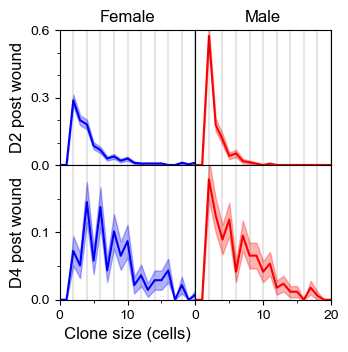

In [3]:
alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]

errmult = 1

plt.figure(figsize = (3.5,3.5))
plt.subplot(2,2,1)
N = len(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'b')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'b', alpha = 0.3)
plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.6])
plt.xlim([0,20])
plt.yticks([0,0.3,0.6])
plt.yticks([0,0.1,0.2,0.3,0.4,0.5,0.6], minor = True)
#plt.xticks([0,10,20])
#plt.xticks([0,5,10,15,20], minor = True)
plt.xticks([])
plt.title('Female')
plt.ylabel('D2 post wound')

plt.subplot(2,2,2)
N = len(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 2)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 2)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'r')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'r', alpha = 0.3)

plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.6])
plt.xlim([0,20])
#plt.yticks([0,0.3,0.6])
#plt.yticks([0,0.1,0.2,0.3,0.4,0.5,0.6], minor = True)
#plt.xticks([0,10,20])
#plt.xticks([0,5,10,15,20], minor = True)
plt.xticks([])
plt.yticks([])
plt.title('Male')

plt.subplot(2,2,3)
N = len(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 4)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 4)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'b')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'b', alpha = 0.3)

plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.2])
plt.xlim([0,20])
plt.yticks([0,0.1])
plt.yticks([0,0.05,0.1,0.15,0.2], minor = True)
plt.xticks([0,10])
plt.xticks([0,5,10,15,20], minor = True)
plt.xlabel('Clone size (cells)')
plt.ylabel('D4 post wound')

plt.subplot(2,2,4)
N = len(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 4)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 4)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'r')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'r', alpha = 0.3)

plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.2])
plt.xlim([0,20])
#plt.yticks([0,0.2,0.4])
#plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
plt.yticks([])

plt.subplots_adjust(hspace=0, wspace=0)
plt.savefig(f'Fig3_WH.pdf', dpi = 400, bbox_inches = 'tight')


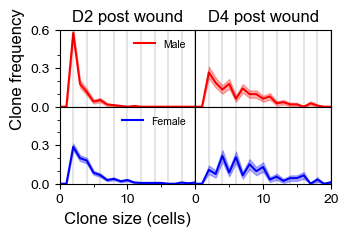

In [4]:
alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 2)]

errmult = 1

plt.figure(figsize = (3.5,2.0))
plt.subplot(2,2,1)
N = len(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 2)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 2)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'r')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'r', alpha = 0.3)
plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.xlim([0,20])
plt.ylim([0,0.4])
plt.yticks([0,0.3,0.6])
plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
#plt.xticks([0,10,20])
#plt.xticks([0,5,10,15,20], minor = True)
plt.xticks([])
plt.legend(['Male'], frameon = False)
plt.title('Male')
plt.title('D2 post wound')
plt.ylabel('Clone frequency')

plt.subplot(2,2,2)
N = len(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 4)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 4)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'r')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'r', alpha = 0.3)
plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.4])
plt.xlim([0,20])
#plt.yticks([0,0.3,0.6])
#plt.yticks([0,0.1,0.2,0.3,0.4,0.5,0.6], minor = True)
#plt.xticks([0,10,20])
#plt.xticks([0,5,10,15,20], minor = True)
plt.xticks([])
plt.yticks([])
plt.title('D4 post wound')

plt.subplot(2,2,3)
N = len(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'b')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'b', alpha = 0.3)
plt.legend(['Female'], frameon = False)
plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.xlim([0,20])
plt.ylim([0,0.6])
plt.yticks([0,0.3])
plt.yticks([0,0.1,0.2,0.3,0.4,0.5,0.6], minor = True)
plt.xticks([0,10])
plt.xticks([0,5,10,15,20], minor = True)
plt.xlabel('Clone size (cells)')

plt.subplot(2,2,4)
N = len(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 4)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 4)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'b')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'b', alpha = 0.3)

plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.4])
plt.xlim([0,20])
#plt.yticks([0,0.2,0.4])
#plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
plt.yticks([])

plt.subplots_adjust(hspace=0, wspace=0)
plt.savefig(f'Fig3_WH.pdf', dpi = 400, bbox_inches = 'tight')


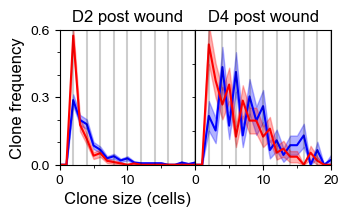

In [5]:
alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]

errmult = 1

plt.figure(figsize = (3.5,1.75))
plt.subplot(1,2,1)
N = len(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 2)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'b')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'b', alpha = 0.3)
plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.6])
plt.xlim([0,20])
plt.yticks([0,0.3,0.6])
plt.yticks([0,0.1,0.2,0.3,0.4,0.5,0.6], minor = True)
#plt.xticks([0,10,20])
#plt.xticks([0,5,10,15,20], minor = True)
plt.xticks([])
plt.title('D2 post wound')

plt.subplot(1,2,1)
N = len(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 2)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 2)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'r')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'r', alpha = 0.3)

plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.6])
plt.xlim([0,20])
plt.xticks([0,10])
plt.xticks([0,5,10,15,20], minor = True)
plt.ylabel('Clone frequency')
plt.xlabel('Clone size (cells)')

#plt.yticks([0,0.3,0.6])
#plt.yticks([0,0.1,0.2,0.3,0.4,0.5,0.6], minor = True)
#plt.xticks([0,10,20])
#plt.xticks([0,5,10,15,20], minor = True)
#plt.xticks([])
#plt.yticks([])

plt.subplot(1,2,2)
N = len(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 4)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'F') & (alldata['temps'] == 4)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'b')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'b', alpha = 0.3)

plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.2])
plt.xlim([0,20])
plt.yticks([0,0.1])
plt.yticks([0,0.05,0.1,0.15,0.2], minor = True)
plt.xticks([0,10])
plt.xticks([0,5,10,15,20], minor = True)
plt.title('D4 post wound')

plt.subplot(1,2,2)
N = len(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 4)]['basal'].values)
vals = np.histogram(alldata[(alldata['sex'] == 'M') & (alldata['temps'] == 4)]['basal'].values, bins = np.arange(50), density=True)
plt.plot(vals[0], color = 'r')
vals = vals[0]
plt.fill_between(np.arange(49), vals-errmult*np.sqrt(vals*(1-vals)/N), vals+errmult*np.sqrt(vals*(1-vals)/N), color = 'r', alpha = 0.3)

plt.vlines(np.arange(0,21,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
plt.ylim([0,0.2])
plt.xlim([0,20])
#plt.yticks([0,0.2,0.4])
#plt.yticks([0,0.1,0.2,0.3,0.4], minor = True)
plt.xticks([0,10,20])
plt.xticks([0,5,10,15,20], minor = True)
plt.yticks([])

plt.subplots_adjust(hspace=0, wspace=0)
plt.savefig(f'Fig2_WH.pdf', dpi = 400, bbox_inches = 'tight')
